# Knowledge Distillation into Analytically Decomposable Students
**Fidelity and explanation validity of sparse PCE/HDMR and tree surrogates on tabular data**

Sena Kılınç 

This single notebook runs the **entire study** and writes every number, table and figure used in the report:

| Step | What happens | Section |
|---|---|---|
| 0 | Settings, paths, experiment configurations | §0 |
| 1 | Data loading, de-duplication, leakage-safe splits | §1 |
| 2 | Metrics: label performance, fidelity, rank agreement | §2 |
| 3 | Student 1 — sparse PCE/HDMR with a data-driven orthonormal basis | §3 |
| 4 | Experiment: teacher → freeze → students → TreeSHAP → bootstrap stability | §4 |
| 5–7 | Run on Online Shoppers (OSPI), UCI-HAR, and 4 extra OSPI splits | §5–§7 |
| 8 | Figures and LaTeX tables, generated only from saved results | §8 |
| 9 | Result tables and key findings (generated text, no hand-typed numbers) | §9 |
| 10 | Copy figures/tables into `../report/` if that folder exists | §10 |

**How to run.** Put the official UCI files in `data/raw/` (see README), then *Run All*. Runtime ≈ 1 min (OSPI), 4 min (HAR), 3 min (extra seeds) on 2 CPU cores.
Outputs go to `outputs/results/`, `outputs/figures/`, `outputs/tables/`.

## 0. Settings

In [1]:
import copy, hashlib, io, itertools, json, platform, time, warnings, zipfile
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
import sklearn
import yaml
from scipy import stats
from sklearn import metrics as M
from sklearn.linear_model import lasso_path
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from IPython.display import display, Markdown

# ---------------- what to run ----------------
RUN_OSPI = True
RUN_HAR = True
RUN_EXTRA_OSPI_SEEDS = True   # 4 more stratified splits for robustness (seeds 1-4)

# ---------------- paths ----------------
ROOT = Path.cwd()
candidates = [ROOT / "data" / "raw", ROOT.parent / "datasets" / "raw"]
RAW = next((p for p in candidates if p.exists()), candidates[0])
OUT = ROOT / "outputs"
for sub in ["results", "figures", "tables"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print("raw data :", RAW)
print("outputs  :", OUT)
print("versions :", {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                     "sklearn": sklearn.__version__, "lightgbm": lgb.__version__, "shap": shap.__version__})

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


raw data : /home/claude/ITU/distilling-into-decomposable-students/data/raw
outputs  : /home/claude/ITU/distilling-into-decomposable-students/outputs
versions : {'python': '3.13.18', 'numpy': '2.5.3', 'pandas': '3.0.5', 'sklearn': '1.9.1', 'lightgbm': '4.7.0', 'shap': '0.54.1'}


### Experiment configurations
Every choice that affects the results is fixed here, **before** any test-set evaluation:
seeds, the teacher's hyper-parameter grid, the PCE basis (degree 3, pairwise HDMR order),
the CART leaf grid, and the shared parsimony rule (pick the least complex student within 0.005 of the
best *validation* macro-F1 against teacher labels).

In [2]:
CONFIGS = {
    "ospi": yaml.safe_load("""
# Online Shoppers Purchasing Intention (UCI id 468) — moderate-dimensional (17 predictors)
dataset: ospi
seed: 0
parsimony_tol: 0.005      # pick the least complex student within 0.005 of best VALIDATION macro-F1 vs teacher labels
topk: [3, 5]
bootstrap: 5
teacher:
  num_leaves_grid: [15, 31, 63]
  learning_rate: 0.03
  max_estimators: 3000
  early_stopping: 100
  min_child_samples: 20
  colsample_bytree: 0.8
pce:
  max_degree: 3           # univariate degree (numeric); categorical = level indicators
  interaction: true       # HDMR order 2 (main + pairwise)
  interaction_degree: 2   # pairwise terms psi_a(x_i)*psi_b(x_j) with deg_a+deg_b <= 2
  screen_top: null        # no screening: all 17 variables enter pairwise candidates
  n_alphas: 40
cart:
  leaf_grid: [2, 4, 8, 16, 32, 64, 128, 256]
  min_samples_leaf: 10
"""),
    "har": yaml.safe_load("""
# UCI HAR (id 240) — high-dimensional (561 engineered features), 6 classes, subject-wise split
dataset: har
seed: 0
parsimony_tol: 0.005
topk: [10, 20]
group_topk: [3, 5]
bootstrap: 5
teacher:
  num_leaves_grid: [15, 31]
  learning_rate: 0.05
  max_estimators: 2000
  early_stopping: 100
  min_child_samples: 20
  colsample_bytree: 0.5
pce:
  max_degree: 3
  interaction: true
  interaction_degree: 2
  screen_top: 30          # training-only screening: top-30 variables of a main-effect PCE enter pairwise terms
  n_alphas: 25
  path_eps: 0.01          # path stops at 1% of alpha_max (full 1e-3 path did not finish in >8 min on 2 CPUs)
  tol: 0.001
cart:
  leaf_grid: [2, 4, 8, 16, 32, 64, 128, 256]
  min_samples_leaf: 10
"""),
}
pd.DataFrame({k: {"seed": v["seed"], "teacher num_leaves grid": v["teacher"]["num_leaves_grid"],
                   "PCE max degree": v["pce"]["max_degree"], "PCE screening": v["pce"]["screen_top"],
                   "CART leaf grid": v["cart"]["leaf_grid"], "bootstrap B": v["bootstrap"]}
              for k, v in CONFIGS.items()})

,ospi,har
seed,0,0
teacher num_leaves grid,"[15, 31, 63]","[15, 31]"
PCE max degree,3,3
PCE screening,None,30
CART leaf grid,"[2, 4, 8, 16, 32, 64, 128, 256]","[2, 4, 8, 16, 32, 64, 128, 256]"
bootstrap B,5,5


## 1. Data: loading, de-duplication and leakage-safe splits
* **OSPI** (UCI id 468): 125 exact duplicate rows are removed *before* splitting; stratified 60/20/20 split.
* **UCI-HAR** (UCI id 240): the official subject-wise train/test split is kept; 5 training subjects are held out for validation, so no person appears in two splits.

Nothing is fitted before the split; every data-driven transform later uses the training part only.

In [3]:
"""Dataset loading and leakage-safe splitting.

Raw files are read from datasets/raw/ (official UCI zips, see datasets/README.md).
All splits are made BEFORE any preprocessing; every data-driven transform
(PCE bases, one-hot levels, teacher, students) is fitted on the training part only.
"""

import hashlib
import io
import zipfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, train_test_split



@dataclass
class Dataset:
    name: str
    X: dict            # split -> DataFrame (raw predictors)
    y: dict            # split -> np.ndarray of int labels
    feature_names: list
    feature_kinds: list   # "numeric" | "categorical"
    class_names: list
    groups: dict | None   # feature -> group name (for group-level comparisons)
    info: dict


def _sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _find(patterns):
    for p in patterns:
        hits = sorted(RAW.glob(p))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"None of {patterns} found in {RAW}. See datasets/README.md")


# --------------------------------------------------------------------------
# UCI Online Shoppers Purchasing Intention (id 468)
# --------------------------------------------------------------------------
OSPI_CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region",
                    "TrafficType", "VisitorType", "Weekend"]


def load_ospi(seed: int = 0, val_frac: float = 0.2, test_frac: float = 0.2) -> Dataset:
    src = _find(["online_shoppers_intention.csv", "*online*shoppers*.zip", "*468*.zip"])
    if src.suffix == ".zip":
        with zipfile.ZipFile(src) as z:
            name = [n for n in z.namelist() if n.endswith(".csv")][0]
            df = pd.read_csv(io.BytesIO(z.read(name)))
    else:
        df = pd.read_csv(src)
    n_raw = len(df)
    n_dup = int(df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)
    y = df.pop("Revenue").astype(int).to_numpy()
    for c in OSPI_CATEGORICAL:
        df[c] = df[c].astype(str)
    feats = list(df.columns)
    kinds = ["categorical" if c in OSPI_CATEGORICAL else "numeric" for c in feats]
    idx = np.arange(len(df))
    i_trv, i_te = train_test_split(idx, test_size=test_frac, stratify=y, random_state=seed)
    i_tr, i_va = train_test_split(i_trv, test_size=val_frac / (1 - test_frac),
                                  stratify=y[i_trv], random_state=seed)
    X = {s: df.iloc[i].reset_index(drop=True) for s, i in
         [("train", i_tr), ("val", i_va), ("test", i_te)]}
    Y = {"train": y[i_tr], "val": y[i_va], "test": y[i_te]}
    info = dict(source=str(src.name), sha256=_sha256(src), n_raw=n_raw,
                n_exact_duplicates_removed=n_dup, n_after_dedup=len(df),
                n_predictors=len(feats), positive_rate=float(y.mean()),
                split="stratified 60/20/20", seed=seed,
                sizes={k: int(len(v)) for k, v in Y.items()})
    return Dataset("ospi", X, Y, feats, kinds, ["no_purchase", "purchase"], None, info)


# --------------------------------------------------------------------------
# UCI HAR (id 240): official subject-wise train/test split
# --------------------------------------------------------------------------
def _har_group(name: str) -> str:
    # e.g. '12 tBodyAcc-mean()-X' -> 'tBodyAcc'; 'angle(tBodyAccMean,gravity)' -> 'angle'
    base = name.split(" ", 1)[1] if " " in name else name
    if base.startswith("angle"):
        return "angle"
    return base.split("-")[0]


def load_har(seed: int = 0, n_val_subjects: int = 5) -> Dataset:
    src = _find(["*human*activity*.zip", "*240*.zip", "UCI HAR Dataset.zip", "UCI HAR Dataset"])

    def read_from(get):
        feats = [l.split() for l in get("features.txt").decode().strip().splitlines()]
        names = [f"{int(i):03d} {n}" for i, n in feats]  # unique (raw names contain duplicates)
        labels = [l.split()[1] for l in get("activity_labels.txt").decode().strip().splitlines()]
        out = {}
        for part in ["train", "test"]:
            Xp = np.loadtxt(io.BytesIO(get(f"{part}/X_{part}.txt")))
            yp = np.loadtxt(io.BytesIO(get(f"{part}/y_{part}.txt")), dtype=int) - 1
            sp = np.loadtxt(io.BytesIO(get(f"{part}/subject_{part}.txt")), dtype=int)
            out[part] = (pd.DataFrame(Xp, columns=names), yp, sp)
        return names, labels, out

    if src.is_dir():
        base = src
        names, labels, out = read_from(lambda p: (base / p).read_bytes())
    else:
        z = zipfile.ZipFile(src)
        inner = [n for n in z.namelist() if n.endswith(".zip")]
        if inner:  # UCI wraps 'UCI HAR Dataset.zip' inside the download
            z = zipfile.ZipFile(io.BytesIO(z.read(inner[0])))
        prefix = [n for n in z.namelist() if n.endswith("features.txt")][0][: -len("features.txt")]
        names, labels, out = read_from(lambda p: z.read(prefix + p))

    Xtr_all, ytr_all, str_all = out["train"]
    Xte, yte, ste = out["test"]
    gss = GroupShuffleSplit(n_splits=1, test_size=n_val_subjects, random_state=seed)
    i_tr, i_va = next(gss.split(Xtr_all, ytr_all, groups=str_all))
    X = {"train": Xtr_all.iloc[i_tr].reset_index(drop=True),
         "val": Xtr_all.iloc[i_va].reset_index(drop=True),
         "test": Xte.reset_index(drop=True)}
    Y = {"train": ytr_all[i_tr], "val": ytr_all[i_va], "test": yte}
    S = {"train": str_all[i_tr], "val": str_all[i_va], "test": ste}
    assert not (set(S["train"]) & set(S["test"])) and not (set(S["val"]) & set(S["test"]))
    assert not (set(S["train"]) & set(S["val"]))
    info = dict(source=str(src.name), sha256=_sha256(src) if src.is_file() else None,
                n_total=int(len(Xtr_all) + len(Xte)), n_predictors=len(names),
                split=f"official subject split; {n_val_subjects} train subjects held out for validation",
                subjects={k: sorted(map(int, set(v))) for k, v in S.items()},
                sizes={k: int(len(v)) for k, v in Y.items()}, seed=seed,
                class_counts={k: np.bincount(v, minlength=6).tolist() for k, v in Y.items()})
    groups = {n: _har_group(n) for n in names}
    return Dataset("har", X, Y, names, ["numeric"] * len(names), labels, groups, info)


def load(name: str, seed: int = 0) -> Dataset:
    return {"ospi": load_ospi, "har": load_har}[name](seed=seed)


def onehot(Xdf: dict, feats, kinds):
    """One-hot for CART (fitted on train levels only). Returns arrays + column->feature map."""
    cats = [f for f, k in zip(feats, kinds) if k == "categorical"]
    levels = {c: sorted(Xdf["train"][c].unique()) for c in cats}
    cols, owner = [], []
    for f, k in zip(feats, kinds):
        if k == "categorical":
            for lv in levels[f]:
                cols.append((f, lv)); owner.append(f)
        else:
            cols.append((f, None)); owner.append(f)
    out = {}
    for s, df in Xdf.items():
        mats = []
        for f, lv in cols:
            mats.append((df[f] == lv).to_numpy(float) if lv is not None else df[f].to_numpy(float))
        out[s] = np.column_stack(mats)
    names = [f if lv is None else f"{f}={lv}" for f, lv in cols]
    return out, names, owner

## 2. Metrics
* **Label performance** (student vs. truth): macro-F1, balanced accuracy, ROC/PR-AUC, Brier, log-loss.
* **Fidelity** (student vs. frozen teacher): decision agreement, macro-F1 against teacher labels, and
  probability-level distances (total variation, KL, Brier-to-teacher).
* **Rank agreement** between global explanations: Spearman, Kendall τ-b, top-k Jaccard.

In [4]:
"""Metrics: label performance, teacher fidelity, explanation agreement."""

import numpy as np
from scipy import stats
from sklearn import metrics as M

EPS = 1e-6  # probability clipping for KL / log-loss


def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def to_proba(raw):
    """raw: (n,) binary log-odds or (n,K) logits -> (n,K) probabilities."""
    raw = np.asarray(raw, float)
    if raw.ndim == 1 or raw.shape[1] == 1:
        p1 = 1.0 / (1.0 + np.exp(-raw.reshape(-1)))
        return np.column_stack([1 - p1, p1])
    return softmax(raw)


def label_metrics(y, P):
    yhat = P.argmax(1)
    K = P.shape[1]
    out = dict(accuracy=M.accuracy_score(y, yhat),
               balanced_accuracy=M.balanced_accuracy_score(y, yhat),
               macro_f1=M.f1_score(y, yhat, average="macro"),
               brier=float(np.mean(np.sum((P - np.eye(K)[y]) ** 2, 1))),
               log_loss=M.log_loss(y, np.clip(P, EPS, 1) / np.clip(P, EPS, 1).sum(1, keepdims=True), labels=list(range(K))))
    if K == 2:
        out.update(roc_auc=M.roc_auc_score(y, P[:, 1]),
                   pr_auc=M.average_precision_score(y, P[:, 1]),
                   pos_precision=M.precision_score(y, yhat, zero_division=0),
                   pos_recall=M.recall_score(y, yhat))
    else:
        out.update(roc_auc_ovr_macro=M.roc_auc_score(y, P, multi_class="ovr", average="macro"))
    return {k: float(v) for k, v in out.items()}


def fidelity_metrics(PT, PS):
    """PT, PS: (n,K) teacher / student probability vectors on the same rows."""
    yt, ys = PT.argmax(1), PS.argmax(1)
    pt, ps = np.clip(PT, EPS, 1), np.clip(PS, EPS, 1)
    pt, ps = pt / pt.sum(1, keepdims=True), ps / ps.sum(1, keepdims=True)
    return dict(
        agreement=float(np.mean(yt == ys)),                       # higher better
        macro_f1_vs_teacher=float(M.f1_score(yt, ys, average="macro")),
        tv_distance=float(np.mean(0.5 * np.abs(PT - PS).sum(1))),  # lower better, in [0,1]
        kl_teacher_student=float(np.mean(np.sum(pt * np.log(pt / ps), 1))),  # lower better
        brier_to_teacher=float(np.mean(np.sum((PT - PS) ** 2, 1))),          # lower better
    )


def rank_agreement(a, b, names=None, ks=(5, 10)):
    """Compare two global importance vectors over the same features."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    out = dict(spearman=float(stats.spearmanr(a, b).statistic),
               kendall_tau_b=float(stats.kendalltau(a, b, variant="b").statistic))
    for k in ks:
        ta, tb = set(np.argsort(-a)[:k]), set(np.argsort(-b)[:k])
        out[f"top{k}_jaccard"] = len(ta & tb) / len(ta | tb)
    return out


def normalise(v):
    v = np.asarray(v, float)
    s = v.sum()
    return v / s if s > 0 else v

## 3. Student 1 — sparse PCE / HDMR
* Each input gets a **data-driven orthonormal basis** built by Gram–Schmidt (QR) on its *training* marginal (arbitrary-PCE idea): numeric inputs use monomials up to degree 3, categorical inputs use level indicators.
* Multivariate terms = products of univariate functions → **HDMR truncated at order 2** (main effects + pairwise terms).
* **Sparsity:** lasso path (multi-task for multiclass), then OLS refit on each active set (hybrid LAR idea); model size chosen on validation.
* **Explanations:** Sobol' indices from squared coefficients, $S_j^T=\sum_{\alpha\ni j}c_\alpha^2/\sum_{\alpha\neq0}c_\alpha^2$ — valid only if the basis is orthonormal, i.e. under independent inputs.
  We therefore also report the diagnostic $\rho=\sum c^2/\widehat{\mathrm{Var}}[\hat z]$ (=1 if orthonormal) and a covariance (ANCOVA-type) index that sums to 1 under dependence.

In [5]:
"""Sparse PCE / HDMR student.

Design (see report Sec. 3):
* Each input X_j gets a data-driven univariate orthonormal basis {psi_{j,d}}
  built by Gram-Schmidt (QR) on the *training* empirical marginal of X_j
  (arbitrary-PCE idea, Oladyshkin & Nowak 2012). Numeric inputs use monomials
  of a (optionally log1p-transformed, standardised) value up to degree p;
  categorical inputs use level indicators (rare levels merged).
* Multivariate terms are products of univariate basis functions of distinct
  variables (HDMR truncation: main effects + pairwise interactions).
  These products are orthonormal only under the *product* of the marginals,
  i.e. if inputs are independent. We measure how far this is from true on the
  data (orthogonality defect) instead of assuming it.
* Sparse selection: lasso path (multi-task for multiclass, shared support),
  followed by OLS refit on the active set ("hybrid" LAR/lasso-OLS idea of
  Blatman & Sudret 2011). Model size chosen on the validation split.
* Sobol' indices from squared coefficients (Sudret 2008), aggregated over
  output components (classes) by summing partial variances.
"""

import itertools
from dataclasses import dataclass, field

import numpy as np
from scipy import stats
from sklearn.linear_model import lasso_path


# --------------------------------------------------------------------------
# Univariate data-driven orthonormal bases
# --------------------------------------------------------------------------
@dataclass
class UnivariateBasis:
    name: str
    kind: str  # "numeric" | "categorical"
    degree: int = 0
    log1p: bool = False
    mu: float = 0.0
    sd: float = 1.0
    levels: list = field(default_factory=list)  # categorical kept levels
    R_inv: np.ndarray | None = None  # maps raw monomials/indicators -> orthonormal

    def raw(self, x: np.ndarray) -> np.ndarray:
        """Raw design [1, m_1, ..., m_D] before orthonormalisation."""
        if self.kind == "numeric":
            t = np.asarray(x, dtype=float)
            if self.log1p:
                t = np.log1p(np.clip(t, 0, None))
            t = (t - self.mu) / self.sd
            cols = [np.ones_like(t)] + [t ** d for d in range(1, self.degree + 1)]
        else:
            x = np.asarray(x).astype(str)
            known = np.isin(x, self.levels)
            x = np.where(known, x, "__other__")
            # first kept level is the reference (absorbed in the constant)
            cols = [np.ones(len(x))] + [(x == lv).astype(float) for lv in self.levels[1:]]
        return np.column_stack(cols)

    def transform(self, x: np.ndarray) -> np.ndarray:
        """Orthonormal non-constant basis functions, shape (n, D)."""
        return (self.raw(x) @ self.R_inv)[:, 1:]


def fit_univariate(x: np.ndarray, name: str, kind: str, max_degree: int,
                   rare_frac: float = 0.01) -> UnivariateBasis | None:
    n = len(x)
    if kind == "numeric":
        x = np.asarray(x, dtype=float)
        nunique = len(np.unique(x))
        if nunique < 2:
            return None
        deg = int(min(max_degree, nunique - 1))
        b = UnivariateBasis(name, "numeric", degree=deg)
        if x.min() >= 0 and stats.skew(x) > 2.0:
            b.log1p = True
        t = np.log1p(np.clip(x, 0, None)) if b.log1p else x
        b.mu, b.sd = float(t.mean()), float(t.std() + 1e-12)
    else:
        xs = np.asarray(x).astype(str)
        vals, counts = np.unique(xs, return_counts=True)
        order = np.argsort(-counts)
        vals, counts = vals[order], counts[order]
        kept = [v for v, c in zip(vals, counts) if c / n >= rare_frac]
        if len(kept) < len(vals):
            kept.append("__other__")
        if len(kept) < 2:
            return None
        b = UnivariateBasis(name, "categorical", degree=1, levels=kept)
    M = b.raw(x)
    # Gram-Schmidt via QR under the empirical measure (weights 1/n)
    Q, R = np.linalg.qr(M / np.sqrt(n))
    # drop numerically dependent columns
    keep = np.abs(np.diag(R)) > 1e-8 * np.abs(R[0, 0])
    if keep.sum() < 2:
        return None
    if not keep.all():
        M = M[:, keep]
        if b.kind == "numeric":
            b.degree = int(keep.sum() - 1)
        else:
            b.levels = [b.levels[0]] + [lv for lv, k in zip(b.levels[1:], keep[1:]) if k]
        Q, R = np.linalg.qr(M / np.sqrt(n))
    sign = np.sign(np.diag(R))
    sign[sign == 0] = 1
    R = R * sign[:, None]
    b.R_inv = np.linalg.inv(R)
    return b


# --------------------------------------------------------------------------
# Multivariate sparse PCE
# --------------------------------------------------------------------------
@dataclass
class Term:
    vars: tuple          # variable indices
    degs: tuple          # per-variable basis index (1-based degree / level index)

    @property
    def order(self):
        return len(self.vars)

    @property
    def total_degree(self):
        return int(sum(self.degs))


class SparsePCE:
    def __init__(self, var_names, var_kinds, max_degree=3, interaction=True,
                 interaction_degree=2, screen_top=None, n_alphas=40,
                 eps=1e-3, parsimony_tol=0.005, random_state=0, tol=1e-4):
        self.var_names = list(var_names)
        self.var_kinds = list(var_kinds)
        self.max_degree = max_degree
        self.interaction = interaction
        self.interaction_degree = interaction_degree
        self.screen_top = screen_top
        self.n_alphas = n_alphas
        self.eps = eps
        self.parsimony_tol = parsimony_tol
        self.random_state = random_state
        self.tol = tol

    # ---- basis ---------------------------------------------------------
    def _fit_bases(self, Xtr):
        self.bases = {}
        for j, (nm, kd) in enumerate(zip(self.var_names, self.var_kinds)):
            b = fit_univariate(Xtr[:, j], nm, kd, self.max_degree)
            if b is not None:
                self.bases[j] = b

    def _uni(self, X):
        return {j: b.transform(X[:, j]) for j, b in self.bases.items()}

    def _design(self, U, terms):
        cols = []
        for t in terms:
            c = np.ones(next(iter(U.values())).shape[0])
            for v, d in zip(t.vars, t.degs):
                c = c * U[v][:, d - 1]
            cols.append(c)
        return np.column_stack(cols) if cols else np.zeros((0, 0))

    def _main_terms(self, vars_):
        out = []
        for j in vars_:
            for d in range(1, self.n_basis[j] + 1):
                out.append(Term((j,), (d,)))
        return out

    def _pair_terms(self, vars_):
        out = []
        for a, b in itertools.combinations(sorted(vars_), 2):
            Da = self.n_basis[a]
            Db = self.n_basis[b]
            for da in range(1, Da + 1):
                for db in range(1, Db + 1):
                    # categorical basis functions count as degree 1
                    ga = da if self.bases[a].kind == "numeric" else 1
                    gb = db if self.bases[b].kind == "numeric" else 1
                    if ga + gb <= self.interaction_degree:
                        out.append(Term((a, b), (da, db)))
        return out

    # ---- fitting -------------------------------------------------------
    def _path_select(self, Phi_tr, Ytr, Phi_va, Yva, score_fn):
        """Lasso path on standardised design, OLS refit on each active set,
        pick the sparsest model within parsimony_tol of best validation score."""
        sc = Phi_tr.std(0) + 1e-12
        A = Phi_tr / sc
        Ym = Ytr.mean(0)
        alphas, coefs, _ = lasso_path(A - A.mean(0), Ytr - Ym, n_alphas=self.n_alphas,
                                      eps=self.eps, max_iter=3000, tol=self.tol)
        # coefs: (n_targets, n_features, n_alphas) or (n_features, n_alphas)
        if coefs.ndim == 2:
            coefs = coefs[None]
        seen, cands = set(), []
        for k in range(coefs.shape[2]):
            act = np.where(np.any(np.abs(coefs[:, :, k]) > 0, axis=0))[0]
            key = tuple(act)
            if len(act) == 0 or key in seen:
                continue
            seen.add(key)
            coef, intercept = self._ols(Phi_tr[:, act], Ytr)
            pred_va = intercept + Phi_va[:, act] @ coef
            cands.append(dict(active=act, coef=coef, intercept=intercept,
                              n_terms=len(act), val_score=score_fn(Yva, pred_va),
                              alpha=float(alphas[k])))
        best = max(c["val_score"] for c in cands)
        ok = [c for c in cands if c["val_score"] >= best - self.parsimony_tol]
        chosen = min(ok, key=lambda c: c["n_terms"])
        return chosen, cands

    @staticmethod
    def _ols(Phi, Y, ridge=1e-8):
        n = Phi.shape[0]
        Z = np.column_stack([np.ones(n), Phi])
        G = Z.T @ Z / n
        G[np.diag_indices_from(G)] += ridge
        beta = np.linalg.solve(G, Z.T @ Y / n)
        return beta[1:], beta[0]

    def fit(self, Xtr, Ytr, Xva, Yva, score_fn):
        """Ytr: (n, K) teacher (centred) logits. score_fn(Y_true, Y_pred) -> higher better."""
        Ytr = np.asarray(Ytr, float).reshape(len(Ytr), -1)
        Yva = np.asarray(Yva, float).reshape(len(Yva), -1)
        self._fit_bases(Xtr)
        self.n_basis = {j: b.transform(Xtr[:2, j]).shape[1] for j, b in self.bases.items()}
        Utr, Uva = self._uni(Xtr), self._uni(Xva)
        all_vars = sorted(self.bases)
        main = self._main_terms(all_vars)
        self.screen_info = None
        # Stage 1 (optional screening): main-effect model, keep top variables
        if self.interaction:
            if self.screen_top is not None and len(all_vars) > self.screen_top:
                ch, _ = self._path_select(self._design(Utr, main), Ytr,
                                          self._design(Uva, main), Yva, score_fn)
                pv = np.zeros(len(self.var_names))
                for i, a in enumerate(ch["active"]):
                    pv[main[a].vars[0]] += np.sum(ch["coef"][i] ** 2)
                order = np.argsort(-pv)
                inter_vars = [int(v) for v in order[: self.screen_top] if pv[v] > 0]
                self.screen_info = dict(n_screened=len(inter_vars),
                                        screened=[self.var_names[v] for v in inter_vars])
            else:
                inter_vars = all_vars
            cand = main + self._pair_terms(inter_vars)
        else:
            cand = main
        self.candidate_terms = cand
        Phi_tr, Phi_va = self._design(Utr, cand), self._design(Uva, cand)
        chosen, self.path_ = self._path_select(Phi_tr, Ytr, Phi_va, Yva, score_fn)
        self.terms = [cand[a] for a in chosen["active"]]
        self.coef_ = chosen["coef"]          # (n_terms, K)
        self.intercept_ = chosen["intercept"]  # (K,)
        self.alpha_ = chosen["alpha"]
        # orthogonality diagnostics on training data
        Phi_sel = Phi_tr[:, chosen["active"]]
        G = Phi_sel.T @ Phi_sel / len(Phi_sel) - np.outer(Phi_sel.mean(0), Phi_sel.mean(0))
        off = G - np.diag(np.diag(G))
        pred_tr = self.intercept_ + Phi_sel @ self.coef_
        self.diagnostics_ = dict(
            n_candidate_terms=len(cand),
            n_terms=len(self.terms),
            max_abs_offdiag_cov=float(np.abs(off).max()) if len(off) > 1 else 0.0,
            mean_abs_offdiag_cov=float(np.abs(off).sum() / max(1, off.size - len(off))),
            # sum c^2 equals Var(f) only if the selected basis is orthonormal
            sum_coef2_over_empirical_var=float(np.sum(self.coef_ ** 2) / np.sum(pred_tr.var(0))),
        )
        return self

    def reselect(self, Xb, Yb):
        """Bootstrap refit: lasso at the chosen alpha on the full candidate set
        (support may change), then OLS on the new support. Bases are kept fixed."""
        from sklearn.linear_model import Lasso, MultiTaskLasso
        Yb = np.asarray(Yb, float).reshape(len(Yb), -1)
        Phi = self._design(self._uni(Xb), self.candidate_terms)
        sc = Phi.std(0) + 1e-12
        A = Phi / sc
        A = A - A.mean(0)
        Yc = Yb - Yb.mean(0)
        if Yb.shape[1] == 1:
            m = Lasso(alpha=self.alpha_, max_iter=3000, tol=self.tol).fit(A, Yc[:, 0])
            act = np.where(np.abs(m.coef_) > 0)[0]
        else:
            m = MultiTaskLasso(alpha=self.alpha_, max_iter=3000, tol=self.tol).fit(A, Yc)
            act = np.where(np.any(np.abs(m.coef_) > 0, axis=0))[0]
        new = SparsePCE.__new__(SparsePCE)
        new.__dict__.update(self.__dict__)
        new.terms = [self.candidate_terms[a] for a in act]
        new.coef_, new.intercept_ = self._ols(Phi[:, act], Yb)
        return new

    def refit_fixed(self, Xtr, Ytr):
        """Refit coefficients on the selected support (used for bootstrap stability)."""
        Ytr = np.asarray(Ytr, float).reshape(len(Ytr), -1)
        Phi = self._design(self._uni(Xtr), self.terms)
        self.coef_, self.intercept_ = self._ols(Phi, Ytr)
        return self

    def predict_raw(self, X):
        Phi = self._design(self._uni(X), self.terms)
        return self.intercept_ + Phi @ self.coef_

    # ---- analytic sensitivity -----------------------------------------
    def sobol(self):
        """First-order, total and pairwise indices from squared coefficients,
        aggregated over outputs: S_u = sum_k V_{u,k} / sum_k V_k."""
        c2 = np.sum(self.coef_ ** 2, axis=1)  # (n_terms,) summed over classes
        V = c2.sum()
        d = len(self.var_names)
        S1, ST = np.zeros(d), np.zeros(d)
        pairs = {}
        for t, v in zip(self.terms, c2):
            if t.order == 1:
                S1[t.vars[0]] += v
            else:
                key = tuple(self.var_names[i] for i in t.vars)
                pairs[key] = pairs.get(key, 0.0) + v / V
            for j in t.vars:
                ST[j] += v
        return S1 / V, ST / V, pairs

    def _deg(self, t):
        # polynomial degree; a categorical level indicator counts as degree 1
        return int(sum(d if self.bases[v].kind == "numeric" else 1 for v, d in zip(t.vars, t.degs)))

    def cov_indices(self, X):
        """Covariance-based (ANCOVA-type) decomposition on the rows X:
        Var(f) = sum_alpha Cov(g_alpha, f),  g_alpha = c_alpha * Psi_alpha.
        Unlike sum c^2, these shares sum to 1 exactly even for dependent inputs
        (they mix 'structural' and 'correlative' contributions; individual
        shares can be negative). Aggregated over classes like sobol()."""
        Phi = self._design(self._uni(X), self.terms)
        F = Phi @ self.coef_
        Fc = F - F.mean(0)
        V = np.sum(Fc.var(0))
        Phic = Phi - Phi.mean(0)
        # Cov(g_alpha,k , f_k) summed over k
        share = np.einsum("na,ak,nk->a", Phic, self.coef_, Fc) / len(X) / V
        d = len(self.var_names)
        C1, CT = np.zeros(d), np.zeros(d)
        for t, s in zip(self.terms, share):
            if t.order == 1:
                C1[t.vars[0]] += s
            for j in t.vars:
                CT[j] += s
        return C1, CT, float(share.sum())

    def complexity(self):
        vars_ = sorted({v for t in self.terms for v in t.vars})
        return dict(n_terms=len(self.terms),
                    n_active_vars=len(vars_),
                    n_interaction_terms=sum(t.order == 2 for t in self.terms),
                    max_interaction_order=max((t.order for t in self.terms), default=0),
                    max_total_degree=max((self._deg(t) for t in self.terms), default=0),
                    n_outputs=int(self.coef_.shape[1]))

## 4. The experiment
`run_experiment(cfg)` performs, in order:
1. load + split; 2. **teacher** (LightGBM, grid + early stopping on validation) → saved and **frozen**;
3. **Student 1** (sparse PCE on teacher logits) and **Student 2** (CART regression tree on teacher probabilities, leaf sweep, plus a same-size tree trained on labels as a control), both selected by the same validation rule;
4. **explanations**: PCE Sobol' (+ covariance index), CART impurity importance, **TreeSHAP** on the teacher (test rows, same logit scale);
5. **agreement** (Spearman, Kendall, top-k Jaccard; HAR also at 18 signal-group level);
6. **bootstrap stability** of the students (teacher fixed); 7. failure-analysis material; 8. everything saved to `outputs/results/<dataset>/results.json`.

In [6]:
"""End-to-end experiment for one dataset.

    python -m kdpce.run --config configs/ospi.yaml

Order of operations (leakage control):
  1. load + split (train/val/test) BEFORE any fitting
  2. teacher: LightGBM, hyper-parameters chosen on val, then FROZEN
  3. teacher outputs on train -> student targets; val -> model selection only;
     test -> final evaluation only
  4. students: sparse PCE/HDMR (teacher logits) and CART surrogate (teacher probabilities)
  5. explanations: Sobol' (PCE), impurity importance (CART), TreeSHAP (teacher)
  6. bootstrap stability of students (teacher fixed)
"""

import warnings
import json
import platform
import time
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
import shap
import sklearn
import yaml
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*eval_set.*")


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


# --------------------------------------------------------------------------
def teacher_frame(ds, split):
    X = ds.X[split].copy()
    for f, k in zip(ds.feature_names, ds.feature_kinds):
        if k == "categorical":
            cats = sorted(ds.X["train"][f].unique())
            X[f] = pd.Categorical(X[f].where(X[f].isin(cats)), categories=cats)
    # LightGBM rejects JSON special characters (HAR names contain ',()'):
    # use positional names; the mapping back is the column order of ds.feature_names
    X.columns = [f"f{i:03d}" for i in range(X.shape[1])]
    return X


def train_teacher(ds, cfg, seed):
    K = len(ds.class_names)
    Xtr, Xva = teacher_frame(ds, "train"), teacher_frame(ds, "val")
    best = None
    for nl in cfg["num_leaves_grid"]:
        params = dict(n_estimators=cfg["max_estimators"], learning_rate=cfg["learning_rate"],
                      num_leaves=nl, min_child_samples=cfg["min_child_samples"],
                      subsample=0.8, subsample_freq=1, colsample_bytree=cfg["colsample_bytree"],
                      reg_lambda=1.0, random_state=seed, verbose=-1, n_jobs=-1)
        if K > 2:
            params["objective"] = "multiclass"
        m = lgb.LGBMClassifier(**params)
        m.fit(Xtr, ds.y["train"], eval_set=[(Xva, ds.y["val"])],
              callbacks=[lgb.early_stopping(cfg["early_stopping"], verbose=False)])
        score = m.best_score_["valid_0"]["multi_logloss" if K > 2 else "binary_logloss"]
        log(f"  teacher num_leaves={nl} best_iter={m.best_iteration_} val_logloss={score:.4f}")
        if best is None or score < best[0]:
            best = (score, nl, m)
    return best[2], dict(num_leaves=best[1], best_iteration=int(best[2].best_iteration_),
                         val_logloss=float(best[0]))


def teacher_raw(model, ds, split):
    z = model.predict(teacher_frame(ds, split), raw_score=True)
    z = np.asarray(z, float)
    if z.ndim == 2:  # multiclass: remove the softmax-invariant per-row mean
        z = z - z.mean(1, keepdims=True)
    return z


def selection_score(z_teacher, z_student):
    """Model-selection criterion (validation only): macro-F1 of student decisions
    against teacher decisions. Class-balanced, so a student cannot score well by
    copying only the majority class on imbalanced data."""
    from sklearn.metrics import f1_score
    return float(f1_score(to_proba(z_teacher).argmax(1), to_proba(z_student).argmax(1), average="macro"))


# --------------------------------------------------------------------------
def tree_proba(tree, X, K):
    p = np.clip(tree.predict(X), 0, 1)
    if K == 2:
        p = p.reshape(-1)
        return np.column_stack([1 - p, p])
    p = p.reshape(len(X), K)
    s = p.sum(1, keepdims=True)
    return np.where(s > 0, p / np.where(s > 0, s, 1), 1.0 / K)


def tree_complexity(tree, used_cols, owner):
    return dict(n_leaves=int(tree.get_n_leaves()), depth=int(tree.get_depth()),
                n_internal_nodes=int(tree.tree_.node_count - tree.get_n_leaves()),
                n_features_used=len({owner[c] for c in used_cols}))


def group_importance(imp_cols, owner, feats):
    out = dict.fromkeys(feats, 0.0)
    for v, f in zip(imp_cols, owner):
        out[f] += v
    return np.array([out[f] for f in feats])


def shap_global(model, ds, split, K):
    ex = shap.TreeExplainer(model)  # tree_path_dependent, raw (log-odds / logit) output
    sv = ex.shap_values(teacher_frame(ds, split))
    sv = np.asarray(sv)
    if K > 2:
        if sv.shape[0] == K and sv.ndim == 3:   # list-style (K, n, d)
            sv = np.transpose(sv, (1, 2, 0))
        sv = sv - sv.mean(2, keepdims=True)     # SHAP of centred logits (linearity)
        return np.abs(sv).mean(0).sum(1)        # sum over classes of mean |phi|
    if sv.ndim == 3:
        sv = sv[..., 1] if sv.shape[-1] == 2 else sv[1]
    return np.abs(sv).mean(0)


def group_vec(vec, feats, groups):
    names = sorted(set(groups[f] for f in feats))
    g = dict.fromkeys(names, 0.0)
    for v, f in zip(vec, feats):
        g[groups[f]] += v
    return names, np.array([g[n] for n in names])


# --------------------------------------------------------------------------
def run_experiment(cfg_in, seed_override=None, bootstrap_override=None):
    cfg = copy.deepcopy(cfg_in)
    if seed_override is not None:
        cfg["seed"] = seed_override
    if bootstrap_override is not None:
        cfg["bootstrap"] = bootstrap_override
    seed = cfg["seed"]
    np.random.seed(seed)
    out = OUT / "results" / (cfg["dataset"] if seed_override is None else f"{cfg['dataset']}_seed{seed}")
    out.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    ds = load(cfg["dataset"], seed=seed)
    K = len(ds.class_names)
    feats = ds.feature_names
    log(f"loaded {ds.name}: {ds.info['sizes']}")
    res = dict(dataset=ds.name, config=cfg, data_info=ds.info,
               env=dict(python=platform.python_version(), numpy=np.__version__,
                        sklearn=sklearn.__version__, lightgbm=lgb.__version__,
                        shap=shap.__version__))

    # ---------------- teacher (then frozen) ----------------
    teacher, tinfo = train_teacher(ds, cfg["teacher"], seed)
    teacher.booster_.save_model(str(out / "teacher_lgbm.txt"))
    Z = {s: teacher_raw(teacher, ds, s) for s in ["train", "val", "test"]}
    PT = {s: to_proba(Z[s]) for s in Z}
    np.savez_compressed(out / "teacher_outputs.npz", **{f"z_{s}": Z[s] for s in Z},
                        **{f"y_{s}": ds.y[s] for s in Z})
    res["teacher"] = dict(**tinfo, test=label_metrics(ds.y["test"], PT["test"]),
                          val=label_metrics(ds.y["val"], PT["val"]))
    log("teacher test", res["teacher"]["test"])

    # ---------------- student 1: sparse PCE/HDMR ----------------
    pcfg = cfg["pce"]
    Xn = {s: ds.X[s].to_numpy(object) for s in ds.X}
    pce = SparsePCE(feats, ds.feature_kinds, max_degree=pcfg["max_degree"],
                    interaction=pcfg["interaction"], interaction_degree=pcfg["interaction_degree"],
                    screen_top=pcfg.get("screen_top"), n_alphas=pcfg["n_alphas"],
                    eps=pcfg.get("path_eps", 1e-3), tol=pcfg.get("tol", 1e-4),
                    parsimony_tol=cfg["parsimony_tol"])
    log("fitting PCE ...")
    pce.fit(Xn["train"], Z["train"], Xn["val"], Z["val"], selection_score)
    zS = {s: pce.predict_raw(Xn[s]) for s in Xn}
    zS = {s: (v[:, 0] if v.shape[1] == 1 else v) for s, v in zS.items()}
    PS_pce = {s: to_proba(zS[s]) for s in zS}
    S1, ST, pairs = pce.sobol()
    # path: complexity vs fidelity (selection on val; test reported descriptively)
    U_te = pce._uni(Xn["test"])
    Phi_te = pce._design(U_te, pce.candidate_terms)
    path = []
    for c in pce.path_:
        zt = c["intercept"] + Phi_te[:, c["active"]] @ c["coef"]
        zt = zt[:, 0] if zt.shape[1] == 1 else zt
        path.append(dict(n_terms=c["n_terms"], alpha=c["alpha"], val_macro_f1_vs_teacher=c["val_score"],
                         **{f"test_{k}": v for k, v in fidelity_metrics(PT["test"], to_proba(zt)).items()}))
    del Phi_te
    r2 = 1 - np.sum((np.atleast_2d(Z["test"].T).T - np.atleast_2d(zS["test"].T).T) ** 2) / \
        np.sum((np.atleast_2d(Z["test"].T).T - np.atleast_2d(Z["test"].T).T.mean(0)) ** 2)
    res["pce"] = dict(
        complexity=pce.complexity(), diagnostics=pce.diagnostics_, screen=pce.screen_info,
        alpha=pce.alpha_, logit_r2_test=float(r2),
        prob_out_of_range="n/a (logit target, probabilities via sigmoid/softmax)",
        test_fidelity=fidelity_metrics(PT["test"], PS_pce["test"]),
        val_fidelity=fidelity_metrics(PT["val"], PS_pce["val"]),
        test_labels=label_metrics(ds.y["test"], PS_pce["test"]),
        path=path,
        top_pairs=sorted(pairs.items(), key=lambda kv: -kv[1])[:10],
        sum_S1=float(S1.sum()))
    log("PCE", res["pce"]["complexity"], res["pce"]["test_fidelity"])

    # ---------------- student 2: CART global surrogate ----------------
    OH, oh_names, owner = onehot(ds.X, feats, ds.feature_kinds)
    tgt = PT["train"][:, 1] if K == 2 else PT["train"]
    ccfg = cfg["cart"]
    sweep = []
    for L in ccfg["leaf_grid"]:
        tr = DecisionTreeRegressor(max_leaf_nodes=L, min_samples_leaf=ccfg["min_samples_leaf"],
                                   random_state=seed).fit(OH["train"], tgt)
        pv, pt_ = tree_proba(tr, OH["val"], K), tree_proba(tr, OH["test"], K)
        # direct-label control at the same leaf budget
        ctl = DecisionTreeClassifier(max_leaf_nodes=L, min_samples_leaf=ccfg["min_samples_leaf"],
                                     random_state=seed).fit(OH["train"], ds.y["train"])
        pc = ctl.predict_proba(OH["test"])
        sweep.append(dict(n_leaves=int(tr.get_n_leaves()), max_leaf_nodes=L, tree=tr,
                          val_macro_f1_vs_teacher=fidelity_metrics(PT["val"], pv)["macro_f1_vs_teacher"],
                          **{f"test_{k}": v for k, v in fidelity_metrics(PT["test"], pt_).items()},
                          test_macro_f1_labels=label_metrics(ds.y["test"], pt_)["macro_f1"],
                          control_test_agreement=fidelity_metrics(PT["test"], pc)["agreement"],
                          control_test_macro_f1_labels=label_metrics(ds.y["test"], pc)["macro_f1"]))
    best = max(s["val_macro_f1_vs_teacher"] for s in sweep)
    chosen = min([s for s in sweep if s["val_macro_f1_vs_teacher"] >= best - cfg["parsimony_tol"]],
                 key=lambda s: s["n_leaves"])
    cart = chosen["tree"]
    PS_cart = {s: tree_proba(cart, OH[s], K) for s in OH}
    used = np.unique(cart.tree_.feature[cart.tree_.feature >= 0])
    cart_imp = group_importance(cart.feature_importances_, owner, feats)
    ctl_chosen = [s for s in sweep if s is chosen][0]
    res["cart"] = dict(
        complexity=tree_complexity(cart, used, owner), max_leaf_nodes=chosen["max_leaf_nodes"],
        test_fidelity=fidelity_metrics(PT["test"], PS_cart["test"]),
        val_fidelity=fidelity_metrics(PT["val"], PS_cart["val"]),
        test_labels=label_metrics(ds.y["test"], PS_cart["test"]),
        label_control_same_leaves=dict(test_agreement=ctl_chosen["control_test_agreement"],
                                       test_macro_f1=ctl_chosen["control_test_macro_f1_labels"]),
        sweep=[{k: v for k, v in s.items() if k != "tree"} for s in sweep])
    log("CART", res["cart"]["complexity"], res["cart"]["test_fidelity"])

    # ---------------- explanations ----------------
    log("TreeSHAP on teacher (test) ...")
    shap_imp = shap_global(teacher, ds, "test", K)
    C1, CT, cov_sum = pce.cov_indices(Xn["test"])
    res["pce"]["cov_indices_sum"] = cov_sum
    res["pce"]["frac_negative_cov_total"] = float(np.mean(CT[CT != 0] < 0)) if np.any(CT != 0) else 0.0
    imp = pd.DataFrame(dict(feature=feats, pce_total_sobol=ST, pce_first_sobol=S1, pce_total_cov=CT,
                            cart_impurity=normalise(cart_imp), teacher_shap=normalise(shap_imp)))
    imp.to_csv(out / "importances.csv", index=False)
    ks = tuple(cfg["topk"])
    agree = {"PCE(ST) vs SHAP": rank_agreement(ST, shap_imp, ks=ks),
             "PCE(S1) vs SHAP": rank_agreement(S1, shap_imp, ks=ks),
             "PCE(cov) vs SHAP": rank_agreement(np.abs(CT), shap_imp, ks=ks),
             "PCE(ST) vs PCE(cov)": rank_agreement(ST, np.abs(CT), ks=ks),
             "CART vs SHAP": rank_agreement(cart_imp, shap_imp, ks=ks),
             "PCE(ST) vs CART": rank_agreement(ST, cart_imp, ks=ks)}
    res["agreement"] = agree
    if ds.groups:
        gn, gS = group_vec(ST, feats, ds.groups)
        _, gC = group_vec(cart_imp, feats, ds.groups)
        _, gV = group_vec(np.abs(CT), feats, ds.groups)
        _, gH = group_vec(shap_imp, feats, ds.groups)
        gks = tuple(cfg.get("group_topk", [3, 5]))
        res["agreement_groups"] = dict(
            n_groups=len(gn),
            **{"PCE(ST) vs SHAP": rank_agreement(gS, gH, ks=gks),
               "PCE(cov) vs SHAP": rank_agreement(gV, gH, ks=gks),
               "CART vs SHAP": rank_agreement(gC, gH, ks=gks),
               "PCE(ST) vs CART": rank_agreement(gS, gC, ks=gks)})
        pd.DataFrame(dict(group=gn, pce_total_sobol=normalise(gS), pce_total_cov_abs=normalise(gV), cart_impurity=normalise(gC),
                          teacher_shap=normalise(gH))).to_csv(out / "importances_groups.csv", index=False)
    log("agreement", json.dumps(agree, indent=1))

    # ---------------- bootstrap stability (teacher frozen) ----------------
    B = cfg["bootstrap"]
    rng = np.random.default_rng(seed)
    n = len(ds.y["train"])
    boot = dict(pce_ST=[], cart_imp=[], pce_fid=[], cart_fid=[], pce_terms=[], cart_leaves=[])
    for b in range(B):
        idx = rng.integers(0, n, n)
        pb = pce.reselect(Xn["train"][idx], np.atleast_2d(Z["train"].T).T[idx])
        zb = pb.predict_raw(Xn["test"]); zb = zb[:, 0] if zb.shape[1] == 1 else zb
        boot["pce_ST"].append(pb.sobol()[1]); boot["pce_terms"].append(len(pb.terms))
        boot["pce_fid"].append(fidelity_metrics(PT["test"], to_proba(zb))["agreement"])
        tb = DecisionTreeRegressor(max_leaf_nodes=chosen["max_leaf_nodes"],
                                   min_samples_leaf=ccfg["min_samples_leaf"],
                                   random_state=seed).fit(OH["train"][idx], tgt[idx])
        boot["cart_imp"].append(group_importance(tb.feature_importances_, owner, feats))
        boot["cart_leaves"].append(int(tb.get_n_leaves()))
        boot["cart_fid"].append(fidelity_metrics(PT["test"], tree_proba(tb, OH["test"], K))["agreement"])
        log(f"  bootstrap {b + 1}/{B}")

    def pairwise(vs):
        rs = [rank_agreement(vs[i], vs[j], ks=ks) for i in range(len(vs)) for j in range(i + 1, len(vs))]
        return {k: [float(np.mean([r[k] for r in rs])), float(np.std([r[k] for r in rs]))] for k in rs[0]}

    res["stability"] = dict(
        B=B, note="student training rows resampled with replacement; teacher, bases and hyper-parameters fixed",
        pce_rank_stability=pairwise(boot["pce_ST"]), cart_rank_stability=pairwise(boot["cart_imp"]),
        pce_test_agreement=[float(np.mean(boot["pce_fid"])), float(np.std(boot["pce_fid"]))],
        cart_test_agreement=[float(np.mean(boot["cart_fid"])), float(np.std(boot["cart_fid"]))],
        pce_n_terms=[float(np.mean(boot["pce_terms"])), float(np.std(boot["pce_terms"]))],
        cart_n_leaves=[float(np.mean(boot["cart_leaves"])), float(np.std(boot["cart_leaves"]))])

    # ---------------- failure analysis material ----------------
    yT = PT["test"].argmax(1)
    fa = {}
    for nm, P in [("pce", PS_pce["test"]), ("cart", PS_cart["test"])]:
        ys = P.argmax(1)
        conf = PT["test"].max(1)
        dis = ys != yT
        fa[nm] = dict(
            disagreement_rate_by_teacher_class={ds.class_names[k]: float(dis[yT == k].mean()) if (yT == k).any() else None
                                                for k in range(K)},
            mean_teacher_conf_on_disagreements=float(conf[dis].mean()) if dis.any() else None,
            mean_teacher_conf_on_agreements=float(conf[~dis].mean()),
            confusion_teacher_vs_student=pd.crosstab(yT, ys).to_dict())
    res["failure"] = fa
    # teacher feature correlation among top features (dependence diagnostic)
    Xnum = ds.X["train"][[f for f, k in zip(feats, ds.feature_kinds) if k == "numeric"]]
    C = np.corrcoef(Xnum.to_numpy(float), rowvar=False)
    off = np.abs(C[np.triu_indices_from(C, 1)])
    res["dependence"] = dict(n_numeric=int(Xnum.shape[1]), frac_pairs_absr_gt_0_8=float(np.mean(off > 0.8)),
                             frac_pairs_absr_gt_0_5=float(np.mean(off > 0.5)), max_abs_r=float(np.nanmax(off)))
    res["runtime_sec"] = time.time() - t0
    json.dump(res, open(out / "results.json", "w"), indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))
    log(f"done in {res['runtime_sec']:.0f}s -> {out / 'results.json'}")
    return res

In [7]:
def summary(res):
    """Compact view of one experiment's results."""
    rows = [("Teacher", res["teacher"]["test"]["macro_f1"], None, None, None,
             f'{res["teacher"]["best_iteration"]} trees x {res["teacher"]["num_leaves"]} leaves')]
    for s, lab in [("pce", "Sparse PCE/HDMR"), ("cart", "CART surrogate")]:
        cx = res[s]["complexity"]
        comp = (f'{cx["n_terms"]} terms ({cx["n_interaction_terms"]} pairwise), {cx["n_active_vars"]} vars' if s == "pce"
                else f'{cx["n_leaves"]} leaves, depth {cx["depth"]}, {cx["n_features_used"]} vars')
        f = res[s]["test_fidelity"]
        rows.append((lab, res[s]["test_labels"]["macro_f1"], f["agreement"], f["macro_f1_vs_teacher"], f["tv_distance"], comp))
    df = pd.DataFrame(rows, columns=["model", "label macro-F1", "agreement", "macro-F1 vs teacher", "TV distance", "complexity"])
    display(df.round(3))
    display(pd.DataFrame(res["agreement"]).T.round(3))
    print(f'rho = sum c^2 / Var = {res["pce"]["diagnostics"]["sum_coef2_over_empirical_var"]:.3f}  (1 = orthonormal basis)')

## 5. Run: Online Shoppers (17 features, binary)

In [8]:
if RUN_OSPI:
    res_ospi = run_experiment(CONFIGS["ospi"])
    summary(res_ospi)

17:14:29 loaded ospi: {'train': 7323, 'val': 2441, 'test': 2441}


17:14:30   teacher num_leaves=15 best_iter=168 val_logloss=0.2446


17:14:30   teacher num_leaves=31 best_iter=155 val_logloss=0.2469


17:14:30   teacher num_leaves=63 best_iter=128 val_logloss=0.2500


17:14:31 teacher test {'accuracy': 0.8992216304793118, 'balanced_accuracy': 0.7696919919953009, 'macro_f1': 0.7923975273813475, 'brier': 0.1401195864700467, 'log_loss': 0.22725325299027546, 'roc_auc': 0.9341188855465342, 'pr_auc': 0.7460133114117198, 'pos_precision': 0.7207792207792207, 'pos_recall': 0.581151832460733}


17:14:31 fitting PCE ...


... (10 outputs left out)

17:14:41 done in 12s -> /home/claude/ITU/distilling-into-decomposable-students/outputs/results/ospi/results.json


,model,label macro-F1,agreement,macro-F1 vs teacher,TV distance,complexity
0,Teacher,0.792,NaN,NaN,NaN,168 trees x 15 leaves
1,Sparse PCE/HDMR,0.789,0.973,0.938,0.025,"80 terms (52 pairwise), 16 vars"
2,CART surrogate,0.792,0.973,0.939,0.026,"128 leaves, depth 12, 14 vars"


,spearman,kendall_tau_b,top3_jaccard,top5_jaccard
PCE(ST) vs SHAP,0.929,0.794,1.0,1.000
PCE(S1) vs SHAP,0.894,0.766,1.0,0.667
PCE(cov) vs SHAP,0.895,0.706,1.0,0.667
PCE(ST) vs PCE(cov),0.926,0.794,1.0,0.667
CART vs SHAP,0.830,0.662,0.5,0.429
PCE(ST) vs CART,0.796,0.587,0.5,0.429


rho = sum c^2 / Var = 0.848  (1 = orthonormal basis)


## 6. Run: UCI-HAR (561 features, 6 classes, subject-wise split)

In [9]:
if RUN_HAR:
    res_har = run_experiment(CONFIGS["har"])
    summary(res_har)

17:14:42 loaded har: {'train': 5619, 'val': 1733, 'test': 2947}


17:14:51   teacher num_leaves=15 best_iter=299 val_logloss=0.0789


17:15:02   teacher num_leaves=31 best_iter=275 val_logloss=0.0806


17:15:02 teacher test {'accuracy': 0.9399389209365456, 'balanced_accuracy': 0.9376602386364662, 'macro_f1': 0.9384229284752484, 'brier': 0.09380779022145264, 'log_loss': 0.17541077500926103, 'roc_auc_ovr_macro': 0.996815166478673}


17:15:03 fitting PCE ...


17:15:43 PCE {'n_terms': 352, 'n_active_vars': 196, 'n_interaction_terms': 70, 'max_interaction_order': 2, 'max_total_degree': 3, 'n_outputs': 6} {'agreement': 0.9395995928062436, 'macro_f1_vs_teacher': 0.938973341707564, 'tv_distance': 0.06181375169335244, 'kl_teacher_student': 0.1579720590580407, 'brier_to_teacher': 0.0636937706248173}


... (8 outputs left out)

17:17:20 done in 159s -> /home/claude/ITU/distilling-into-decomposable-students/outputs/results/har/results.json


,model,label macro-F1,agreement,macro-F1 vs teacher,TV distance,complexity
0,Teacher,0.938,NaN,NaN,NaN,299 trees x 15 leaves
1,Sparse PCE/HDMR,0.942,0.940,0.939,0.062,"352 terms (70 pairwise), 196 vars"
2,CART surrogate,0.832,0.856,0.849,0.157,"16 leaves, depth 6, 14 vars"


,spearman,kendall_tau_b,top10_jaccard,top20_jaccard
PCE(ST) vs SHAP,0.488,0.382,0.333,0.250
PCE(S1) vs SHAP,0.461,0.357,0.176,0.143
PCE(cov) vs SHAP,0.496,0.388,0.250,0.250
PCE(ST) vs PCE(cov),0.990,0.924,0.333,0.481
CART vs SHAP,0.201,0.164,0.111,0.143
PCE(ST) vs CART,0.176,0.161,0.053,0.053


rho = sum c^2 / Var = 4.697  (1 = orthonormal basis)


## 7. Robustness: OSPI on 4 additional stratified splits (seeds 1–4)

In [10]:
if RUN_EXTRA_OSPI_SEEDS:
    for s in [1, 2, 3, 4]:
        run_experiment(CONFIGS["ospi"], seed_override=s)

17:17:20 loaded ospi: {'train': 7323, 'val': 2441, 'test': 2441}


17:17:21   teacher num_leaves=15 best_iter=174 val_logloss=0.2308


17:17:21   teacher num_leaves=31 best_iter=126 val_logloss=0.2326


17:17:21   teacher num_leaves=63 best_iter=127 val_logloss=0.2350


17:17:22 teacher test {'accuracy': 0.9000409668168783, 'balanced_accuracy': 0.7861686275806128, 'macro_f1': 0.8007848142588416, 'brier': 0.1451524755493424, 'log_loss': 0.23677854496755865, 'roc_auc': 0.9275534049213136, 'pr_auc': 0.7289694959681866, 'pos_precision': 0.7053571428571429, 'pos_recall': 0.6204188481675392}


17:17:22 fitting PCE ...


... (58 outputs left out)

17:18:00   bootstrap 3/5


17:18:01   bootstrap 4/5


17:18:01   bootstrap 5/5


17:18:01 done in 11s -> /home/claude/ITU/distilling-into-decomposable-students/outputs/results/ospi_seed4/results.json


## 8. Figures and LaTeX tables
Generated **only** from the saved `results.json` files (no retyped numbers).

In [11]:
RES, FIG, TAB = OUT / "results", OUT / "figures", OUT / "tables"
"""Figures and LaTeX tables generated ONLY from results/*/results.json (no retyped numbers).

    python -m kdpce.figures
"""

import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

# validated categorical palette (dataviz reference instance, slots 1-3)
C = {"PCE": "#2a78d6", "CART": "#eb6834", "SHAP": "#1baf7a"}
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "legend.frameon": False})
NAMES = {"ospi": "Online Shoppers (17 features)", "har": "UCI-HAR (561 features)"}


def load_results(ds):
    return json.load(open(RES / ds / "results.json"))


def tradeoff(rs):
    fig, axes = plt.subplots(1, len(rs), figsize=(7.0, 2.4), sharey=False)
    for ax, (ds, r) in zip(np.atleast_1d(axes), rs.items()):
        p = pd.DataFrame(r["pce"]["path"]).sort_values("n_terms")
        c = pd.DataFrame(r["cart"]["sweep"]).sort_values("n_leaves")
        ax.plot(p["n_terms"], p["test_macro_f1_vs_teacher"], "-o", ms=3, lw=1.5, color=C["PCE"],
                label="sparse PCE/HDMR (x = retained terms)")
        ax.plot(c["n_leaves"], c["test_macro_f1_vs_teacher"], "-s", ms=3, lw=1.5, color=C["CART"],
                label="CART surrogate (x = leaves)")
        sp, sc = r["pce"]["complexity"]["n_terms"], r["cart"]["complexity"]["n_leaves"]
        ax.scatter([sp], [r["pce"]["test_fidelity"]["macro_f1_vs_teacher"]], s=60, facecolor="none",
                   edgecolor=INK, lw=1.2, zorder=5)
        ax.scatter([sc], [r["cart"]["test_fidelity"]["macro_f1_vs_teacher"]], s=60, facecolor="none",
                   edgecolor=INK, lw=1.2, zorder=5)
        ax.set_xscale("log", base=2)
        ax.set_xlabel("structural complexity (log scale)")
        ax.set_title(NAMES[ds], fontsize=8, color=INK)
    np.atleast_1d(axes)[0].set_ylabel("test macro-F1 vs teacher labels")
    np.atleast_1d(axes)[0].legend(loc="lower right", fontsize=7)
    fig.tight_layout()
    fig.savefig(FIG / "tradeoff.pdf"); fig.savefig(FIG / "tradeoff.png", dpi=200)
    plt.show()


def importance(rs):
    fig, axes = plt.subplots(1, len(rs), figsize=(7.0, 2.6))
    for ax, (ds, r) in zip(np.atleast_1d(axes), rs.items()):
        f = RES / ds / ("importances_groups.csv" if ds == "har" else "importances.csv")
        d = pd.read_csv(f)
        key = "group" if "group" in d else "feature"
        for col in ["pce_total_sobol", "cart_impurity", "teacher_shap"]:
            d[col] = d[col] / d[col].sum()
        d = d.sort_values("teacher_shap", ascending=False).head(8)
        y = np.arange(len(d))
        h = 0.26
        for i, (col, lab, cc) in enumerate([("teacher_shap", "teacher TreeSHAP mean|φ|", C["SHAP"]),
                                           ("pce_total_sobol", "PCE total Sobol' $S_T$", C["PCE"]),
                                           ("cart_impurity", "CART impurity", C["CART"])]):
            ax.barh(y + (i - 1) * h, d[col], height=h - 0.03, color=cc, label=lab)
        ax.set_yticks(y, [s if len(s) <= 24 else s[:22] + "…" for s in d[key]])
        ax.set_axisbelow(True)
        ax.invert_yaxis()
        ax.set_xlabel("normalised importance share")
        ax.set_title(NAMES[ds] + (": 18 signal groups" if ds == "har" else ""), fontsize=8, color=INK)
    h_, l_ = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=3, fontsize=7)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig(FIG / "importance.pdf"); fig.savefig(FIG / "importance.png", dpi=200)
    plt.show()


def f3(x):
    return f"{x:.3f}"


def tables(rs):
    TAB.mkdir(parents=True, exist_ok=True)
    rows = []
    for ds, r in rs.items():
        T = r["teacher"]["test"]
        rows.append([NAMES[ds].split(" (")[0], "Teacher (LightGBM)", f3(T["macro_f1"]), f3(T["balanced_accuracy"]),
                     "--", "--", "--", f"{r['teacher']['best_iteration']} trees $\\times$ {r['teacher']['num_leaves']} leaves"])
        for s, lab in [("pce", "Sparse PCE/HDMR"), ("cart", "CART surrogate")]:
            L, F, cx = r[s]["test_labels"], r[s]["test_fidelity"], r[s]["complexity"]
            comp = (f"{cx['n_terms']} terms ({cx['n_interaction_terms']} pairwise), {cx['n_active_vars']} vars"
                    if s == "pce" else f"{cx['n_leaves']} leaves, depth {cx['depth']}, {cx['n_features_used']} vars")
            rows.append(["", lab, f3(L["macro_f1"]), f3(L["balanced_accuracy"]), f3(F["agreement"]),
                         f3(F["macro_f1_vs_teacher"]), f3(F["tv_distance"]), comp])
    body = " \\\\\n".join(" & ".join(x) for x in rows)
    (TAB / "main.tex").write_text(body + " \\\\\n")
    rows = []
    for ds, r in rs.items():
        for k, v in r["agreement"].items():
            ks = [kk for kk in v if kk.startswith("top")]
            rows.append([NAMES[ds].split(" (")[0], k, f3(v["spearman"]), f3(v["kendall_tau_b"])] +
                        [f"{v[kk]:.2f} (k={kk[3:].split('_')[0]})" for kk in ks])
        if "agreement_groups" in r:
            for k, v in r["agreement_groups"].items():
                if k == "n_groups":
                    continue
                ks = [kk for kk in v if kk.startswith("top")]
                rows.append(["", k + f" [{r['agreement_groups']['n_groups']} groups]", f3(v["spearman"]),
                             f3(v["kendall_tau_b"])] + [f"{v[kk]:.2f} (k={kk[3:].split('_')[0]})" for kk in ks])
    (TAB / "agreement.tex").write_text(" \\\\\n".join(" & ".join(x) for x in rows) + " \\\\\n")
    rows = []
    for ds, r in rs.items():
        st, dg = r["stability"], r["pce"]["diagnostics"]
        rows.append([NAMES[ds].split(" (")[0],
                     f"{st['pce_rank_stability']['spearman'][0]:.3f} $\\pm$ {st['pce_rank_stability']['spearman'][1]:.3f}",
                     f"{st['cart_rank_stability']['spearman'][0]:.3f} $\\pm$ {st['cart_rank_stability']['spearman'][1]:.3f}",
                     f"{st['pce_test_agreement'][0]:.3f} $\\pm$ {st['pce_test_agreement'][1]:.3f}",
                     f"{st['cart_test_agreement'][0]:.3f} $\\pm$ {st['cart_test_agreement'][1]:.3f}",
                     f3(dg["sum_coef2_over_empirical_var"]), f"{dg['max_abs_offdiag_cov']:.2f}",
                     f"{r['dependence']['frac_pairs_absr_gt_0_8']:.3f}"])
    (TAB / "stability.tex").write_text(" \\\\\n".join(" & ".join(x) for x in rows) + " \\\\\n")


def seeds_table():
    rows = []
    for s in range(5):
        f = RES / ("ospi" if s == 0 else f"ospi_seed{s}") / "results.json"
        if not f.exists():
            continue
        r = json.load(open(f))
        rows.append(dict(teacher=r["teacher"]["test"]["macro_f1"],
                         pce_agr=r["pce"]["test_fidelity"]["agreement"], pce_terms=r["pce"]["complexity"]["n_terms"],
                         cart_agr=r["cart"]["test_fidelity"]["agreement"], cart_leaves=r["cart"]["complexity"]["n_leaves"],
                         rho=r["pce"]["diagnostics"]["sum_coef2_over_empirical_var"],
                         sp_pce=r["agreement"]["PCE(ST) vs SHAP"]["spearman"], sp_cart=r["agreement"]["CART vs SHAP"]["spearman"],
                         sp_pc=r["agreement"]["PCE(ST) vs CART"]["spearman"],
                         cart_lab=r["cart"]["test_labels"]["macro_f1"], ctl_lab=r["cart"]["label_control_same_leaves"]["test_macro_f1"]))
    d = pd.DataFrame(rows)
    d.to_csv(RES / "ospi_seeds_summary.csv", index=False)
    m, s_ = d.mean(), d.std(ddof=1)
    cell = lambda k, nd=3: f"{m[k]:.{nd}f} $\\pm$ {s_[k]:.{nd}f}"
    line = " & ".join([str(len(d)), cell("teacher"), cell("pce_agr"), cell("pce_terms", 0), cell("cart_agr"),
                       cell("cart_leaves", 0), cell("rho", 2), cell("sp_pce", 2), cell("sp_cart", 2),
                       f"{int((d.cart_lab > d.ctl_lab).sum())}/{len(d)}"])
    (TAB / "seeds.tex").write_text(line + " \\\\\n")
    return d

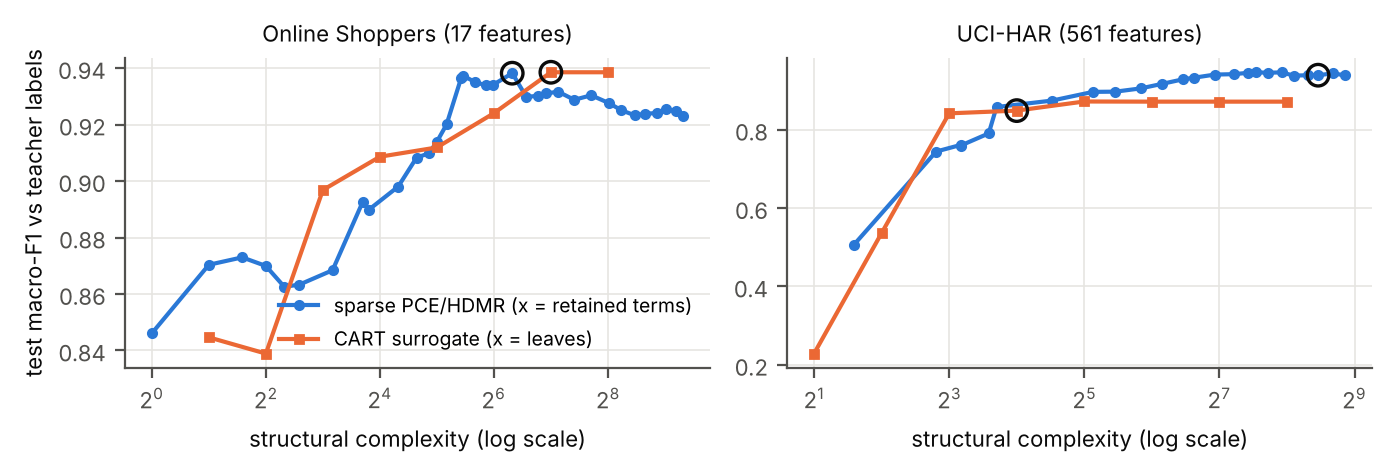

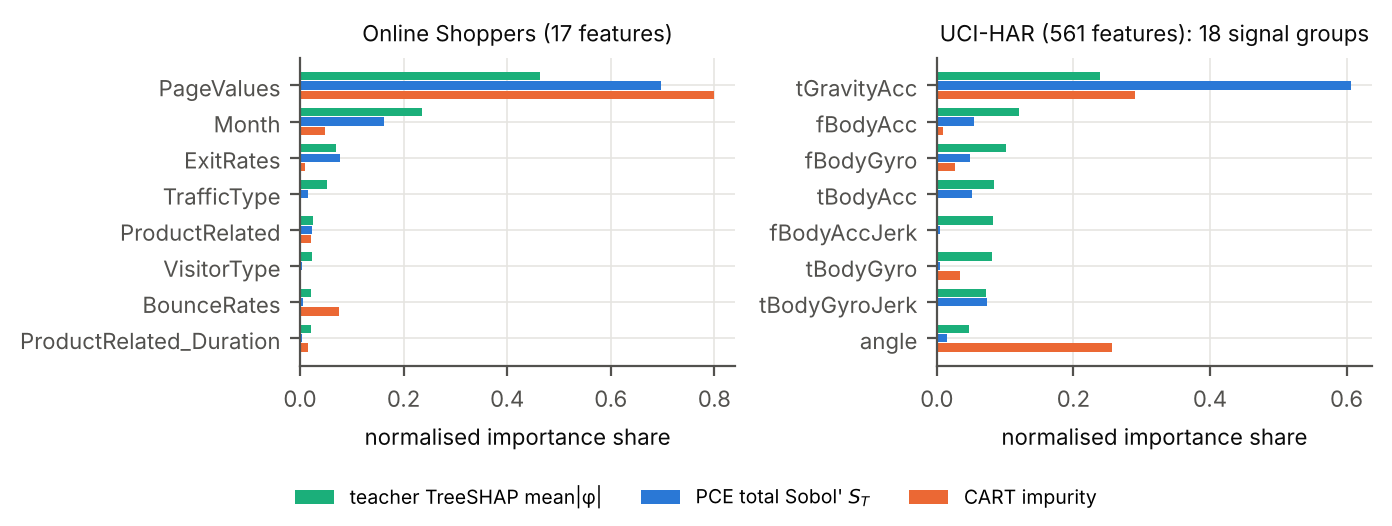

written: ['importance.pdf', 'importance.png', 'tradeoff.pdf', 'tradeoff.png'] ['agreement.tex', 'main.tex', 'seeds.tex', 'stability.tex']


In [12]:
rs = {ds: load_results(ds) for ds in ["ospi", "har"] if (RES / ds / "results.json").exists()}
tradeoff(rs)
importance(rs)
tables(rs)
seeds = seeds_table()
print("written:", sorted(p.name for p in FIG.iterdir()), sorted(p.name for p in TAB.iterdir()))

## 9. Result tables and key findings

In [13]:
rows = []
for ds, r in rs.items():
    for s, lab in [("teacher", "Teacher"), ("pce", "PCE"), ("cart", "CART")]:
        L = r[s]["test"] if s == "teacher" else r[s]["test_labels"]
        F = {} if s == "teacher" else r[s]["test_fidelity"]
        rows.append(dict(dataset=ds, model=lab, label_macro_f1=L["macro_f1"], balanced_acc=L["balanced_accuracy"],
                         agreement=F.get("agreement"), macro_f1_vs_teacher=F.get("macro_f1_vs_teacher"),
                         tv_distance=F.get("tv_distance")))
display(Markdown("**Table A — performance and fidelity (test set)**"))
display(pd.DataFrame(rows).round(3))

display(Markdown("**Table B — explanation agreement (Spearman / top-k Jaccard)**"))
agree = []
for ds, r in rs.items():
    for k, v in r["agreement"].items():
        agree.append(dict(dataset=ds, level="feature", pair=k, **{kk: vv for kk, vv in v.items()}))
    for k, v in r.get("agreement_groups", {}).items():
        if k != "n_groups":
            agree.append(dict(dataset=ds, level="group", pair=k, **v))
display(pd.DataFrame(agree).round(3))

display(Markdown("**Table C — stability and validity diagnostics**"))
display(pd.DataFrame({ds: {"PCE rank stability": r["stability"]["pce_rank_stability"]["spearman"][0],
                           "CART rank stability": r["stability"]["cart_rank_stability"]["spearman"][0],
                           "rho = sum c^2 / Var": r["pce"]["diagnostics"]["sum_coef2_over_empirical_var"],
                           "max off-diag cov": r["pce"]["diagnostics"]["max_abs_offdiag_cov"],
                           "share of |r|>0.8 pairs": r["dependence"]["frac_pairs_absr_gt_0_8"]}
                      for ds, r in rs.items()}).round(3))
if len(seeds) > 1:
    display(Markdown(f"**Table D — OSPI over {len(seeds)} splits (mean ± sd)**"))
    display(pd.DataFrame({"mean": seeds.mean(), "sd": seeds.std(ddof=1)}).round(3))

**Table A — performance and fidelity (test set)**

,dataset,model,label_macro_f1,balanced_acc,agreement,macro_f1_vs_teacher,tv_distance
0,ospi,Teacher,0.792,0.770,NaN,NaN,NaN
1,ospi,PCE,0.789,0.768,0.973,0.938,0.025
2,ospi,CART,0.792,0.769,0.973,0.939,0.026
3,har,Teacher,0.938,0.938,NaN,NaN,NaN
4,har,PCE,0.942,0.941,0.940,0.939,0.062
5,har,CART,0.832,0.834,0.856,0.849,0.157


**Table B — explanation agreement (Spearman / top-k Jaccard)**

,dataset,level,pair,spearman,kendall_tau_b,top3_jaccard,top5_jaccard,top10_jaccard,top20_jaccard
0,ospi,feature,PCE(ST) vs SHAP,0.929,0.794,1.0,1.000,NaN,NaN
1,ospi,feature,PCE(S1) vs SHAP,0.894,0.766,1.0,0.667,NaN,NaN
2,ospi,feature,PCE(cov) vs SHAP,0.895,0.706,1.0,0.667,NaN,NaN
3,ospi,feature,PCE(ST) vs PCE(cov),0.926,0.794,1.0,0.667,NaN,NaN
4,ospi,feature,CART vs SHAP,0.830,0.662,0.5,0.429,NaN,NaN
5,ospi,feature,PCE(ST) vs CART,0.796,0.587,0.5,0.429,NaN,NaN
6,har,feature,PCE(ST) vs SHAP,0.488,0.382,NaN,NaN,0.333,0.250
7,har,feature,PCE(S1) vs SHAP,0.461,0.357,NaN,NaN,0.176,0.143
8,har,feature,PCE(cov) vs SHAP,0.496,0.388,NaN,NaN,0.250,0.250
9,har,feature,PCE(ST) vs PCE(cov),0.990,0.924,NaN,NaN,0.333,0.481


**Table C — stability and validity diagnostics**

,ospi,har
PCE rank stability,0.939,0.791
CART rank stability,0.961,0.420
rho = sum c^2 / Var,0.848,4.697
max off-diag cov,0.793,1.958
share of |r|>0.8 pairs,0.044,0.146


**Table D — OSPI over 5 splits (mean ± sd)**

,mean,sd
teacher,0.800,0.006
pce_agr,0.972,0.001
pce_terms,116.800,46.116
cart_agr,0.972,0.004
cart_leaves,70.400,35.054
rho,0.876,0.088
sp_pce,0.897,0.031
sp_cart,0.812,0.042
sp_pc,0.800,0.039
cart_lab,0.797,0.003


In [14]:
# Key findings written from the numbers above (nothing typed by hand)
o, h = rs["ospi"], rs["har"]
txt = f"""
* **Fidelity.** OSPI: PCE agreement {o['pce']['test_fidelity']['agreement']:.1%}, CART {o['cart']['test_fidelity']['agreement']:.1%}.
  HAR: PCE {h['pce']['test_fidelity']['agreement']:.1%}, CART {h['cart']['test_fidelity']['agreement']:.1%}
  (best CART over the leaf sweep: {max(s['test_agreement'] for s in h['cart']['sweep']):.1%}).
* **Complexity.** OSPI PCE {o['pce']['complexity']['n_terms']} terms vs CART {o['cart']['complexity']['n_leaves']} leaves;
  HAR PCE {h['pce']['complexity']['n_terms']} terms over {h['pce']['complexity']['n_active_vars']} variables vs CART {h['cart']['complexity']['n_leaves']} leaves.
* **Explanations vs TreeSHAP (Spearman).** OSPI: PCE {o['agreement']['PCE(ST) vs SHAP']['spearman']:.2f}, CART {o['agreement']['CART vs SHAP']['spearman']:.2f}.
  HAR features: PCE {h['agreement']['PCE(ST) vs SHAP']['spearman']:.2f}, CART {h['agreement']['CART vs SHAP']['spearman']:.2f};
  HAR groups: PCE {h['agreement_groups']['PCE(ST) vs SHAP']['spearman']:.2f}, CART {h['agreement_groups']['CART vs SHAP']['spearman']:.2f}.
* **Validity of analytic Sobol' indices.** rho = sum c^2 / Var is {o['pce']['diagnostics']['sum_coef2_over_empirical_var']:.2f} on OSPI
  and {h['pce']['diagnostics']['sum_coef2_over_empirical_var']:.2f} on HAR (1 = orthonormal). On HAR the coefficient-based indices are therefore
  not valid variance shares, although the student remains predictively faithful.
* **Stability (bootstrap rank Spearman).** HAR: PCE {h['stability']['pce_rank_stability']['spearman'][0]:.2f}, CART {h['stability']['cart_rank_stability']['spearman'][0]:.2f}.
"""
display(Markdown(txt))


* **Fidelity.** OSPI: PCE agreement 97.3%, CART 97.3%.
  HAR: PCE 94.0%, CART 85.6%
  (best CART over the leaf sweep: 87.7%).
* **Complexity.** OSPI PCE 80 terms vs CART 128 leaves;
  HAR PCE 352 terms over 196 variables vs CART 16 leaves.
* **Explanations vs TreeSHAP (Spearman).** OSPI: PCE 0.93, CART 0.83.
  HAR features: PCE 0.49, CART 0.20;
  HAR groups: PCE 0.75, CART 0.50.
* **Validity of analytic Sobol' indices.** rho = sum c^2 / Var is 0.85 on OSPI
  and 4.70 on HAR (1 = orthonormal). On HAR the coefficient-based indices are therefore
  not valid variance shares, although the student remains predictively faithful.
* **Stability (bootstrap rank Spearman).** HAR: PCE 0.79, CART 0.42.


## 10. Copy figures and tables into the report folder (if present)

In [15]:
import shutil
REPORT = ROOT.parent / "report"
if REPORT.exists():
    for sub in ["figures", "tables"]:
        (REPORT / sub).mkdir(exist_ok=True)
        for f in (OUT / sub).iterdir():
            shutil.copy2(f, REPORT / sub / f.name)
    print("copied to", REPORT, "- recompile the LaTeX report to update it")
else:
    print("no ../report folder; outputs stay in", OUT)

copied to /home/claude/ITU/report - recompile the LaTeX report to update it
